# Welcome to Modal notebooks!

Write Python code and collaborate in real time. Your code runs in Modal's
**serverless cloud**, and anyone in the same workspace can join.

This notebook comes with some common Python libraries installed. Run
cells with `Shift+Enter`.

In [3]:
!modal volume put tvsum-data /path/to/checkpoints.zip /dl/results.zip

⠋ Uploading file(s) to volume...
⠋ Uploading file(s) to volume...
Uploading file(s) to volume... 0:00:00 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ .
╭─ Error ──────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ [Errno 2] No such file or directory: '/path/to/checkpoints.zip'                                              │
╰──────────────────────────────────────────────────────────────────────────────────────────────────────────────╯


In [7]:
%%writefile tvsum_detr.py
"""CG-DETR on TVSum (video+language) via Lighthouse evaluate.py -> per-domain Top-5 mAP."""
import modal  # only module imported locally; everything else is imported inside functions

APP_NAME = "tvsum-detr"
GPU      = "a10g"
DATA     = "/data"
REPO     = "/root/lighthouse"

CKPTS_GDRIVE_ID    = ""                                   # <- option A: your Drive-copy id (leave "" for option B)
FEATURES_GDRIVE_ID = "1gSex1hpXLxHQu6zHyyQISKZjP7Ndt6U9"  # already downloaded earlier; auto-skipped if present

image = (
    modal.Image.debian_slim(python_version="3.10")
    .apt_install("ffmpeg", "git", "wget", "unzip")
    .pip_install("torch==2.1.0", "torchvision==0.16.0", "torchaudio==2.1.0",
                 extra_index_url="https://download.pytorch.org/whl/cu118")
    .pip_install("transformers==4.40.0", "gdown", "numpy", "tqdm", "ftfy", "regex", "einops")
    .run_commands("git clone https://github.com/line/lighthouse.git /root/lighthouse",
                  "pip install -e /root/lighthouse")
)
app = modal.App(APP_NAME, image=image)
vol = modal.Volume.from_name("tvsum-data", create_if_missing=True)


@app.function(volumes={DATA: vol}, timeout=3600)
def setup():
    """Ensure TVSum features + CG-DETR checkpoints are in the Volume (volume -> local zip -> gdown)."""
    import os, glob, shutil, subprocess

    def present_features():
        return bool(glob.glob(f"{DATA}/**/features/tvsum/*", recursive=True))

    def present_ckpts():
        return [p for p in glob.glob(f"{DATA}/results/**/*.ckpt", recursive=True)
                if "cg_detr" in p and "tvsum" in p]

    def ensure(gid, zip_name, present_fn, label):
        if present_fn():
            print(f"{label}: already present"); return
        os.makedirs(f"{DATA}/dl", exist_ok=True)
        zp = f"{DATA}/dl/{zip_name}"
        if not os.path.exists(zp):
            assert gid, (f"\n{label} is missing and no id is set.\n"
                         f"  -> set its *_GDRIVE_ID to your Drive-copy id, OR\n"
                         f"  -> run:  modal volume put tvsum-data ./{zip_name} /dl/{zip_name}\n")
            import gdown
            print(f"{label}: downloading from Drive id {gid} ...")
            try:
                gdown.download(id=gid, output=zp, quiet=False, fuzzy=True)
            except Exception as e:
                raise RuntimeError(f"{label}: gdown failed (likely Drive quota). "
                                   f"Use the 'Make a copy to your Drive' trick or `modal volume put`. ({e})")
        print(f"{label}: unzipping {zp} ...")
        subprocess.run(["bash", "-lc", f"cd {DATA} && (unzip -o -q {zp} || tar xf {zp})"], check=True)

    ensure(FEATURES_GDRIVE_ID, "tvsum_features.zip", present_features, "features")
    for cand in glob.glob(f"{DATA}/**/features/tvsum", recursive=True):     # normalize to /data/features/tvsum
        if cand != f"{DATA}/features/tvsum":
            os.makedirs(f"{DATA}/features", exist_ok=True)
            if not os.path.exists(f"{DATA}/features/tvsum"): shutil.move(cand, f"{DATA}/features/tvsum")
    ensure(CKPTS_GDRIVE_ID, "checkpoints.zip", present_ckpts, "checkpoints")

    print("\n--- cg_detr tvsum checkpoints found ---")
    subprocess.run(["bash", "-lc", f"find {DATA}/results -name '*.ckpt' 2>/dev/null | grep -i tvsum | grep -i cg_detr || echo NONE"])
    print("--- features/tvsum ---")
    subprocess.run(["bash", "-lc", f"ls {DATA}/features/tvsum 2>/dev/null | head || echo NONE"])
    vol.commit()


@app.function(volumes={DATA: vol}, gpu=GPU, timeout=3600)
def run_cgdetr():
    """Lighthouse evaluate.py per TVSum domain -> canonical Top-5 mAP."""
    import os, glob, json, re, subprocess, numpy as np
   # results: checkpoints are at /data/results
    if not os.path.lexists(f"{REPO}/results"):
        os.symlink(f"{DATA}/results", f"{REPO}/results")
    # features: the zip unpacked to /data/tvsum (not /data/features/tvsum) — locate it via clip_text
    cands = glob.glob(f"{DATA}/**/clip_text", recursive=True)
    assert cands, "clip_text features not found under /data — check the features zip contents"
    feat_tvsum = os.path.dirname(cands[0])            # e.g. /data/tvsum
    os.makedirs(f"{REPO}/features", exist_ok=True)
    if not os.path.lexists(f"{REPO}/features/tvsum"):
        os.symlink(feat_tvsum, f"{REPO}/features/tvsum")
    print("features/tvsum ->", feat_tvsum)

    jsonl = glob.glob(f"{REPO}/data/tvsum/*val*.jsonl")[0]
    recs  = [json.loads(l) for l in open(jsonl)]
    domains = sorted({r["domain"] for r in recs})
    ckpts = [p for p in glob.glob(f"{DATA}/results/**/*.ckpt", recursive=True)
             if "cg_detr" in p and "tvsum" in p and "clip_slowfast" in p]
    assert ckpts, "No cg_detr/tvsum/clip_slowfast checkpoint found — run setup() first / supply the checkpoint."
    print("checkpoints:", ckpts)
    subprocess.run(["python", "training/evaluate.py", "--help"], cwd=REPO)   # shows the real CLI

    def ckpt_for(dom):
        per = [c for c in ckpts if f"/{dom}/" in c or c.endswith(f"{dom}.ckpt") or f"_{dom}" in c]
        return (per or ckpts)[0]

    out = {}
    for dom in domains:
        cmd = ["python", "training/evaluate.py", "--model", "cg_detr", "--dataset", "tvsum",
               "--feature", "clip_slowfast", "--split", "val",
               "--model_path", ckpt_for(dom), "--eval_path", jsonl, "--domain", dom]
        r = subprocess.run(cmd, cwd=REPO, capture_output=True, text=True)
        blob = r.stdout + "\n" + r.stderr
        m = re.search(r"mAP['\"]?\s*[:=]\s*([0-9.]+)", blob) or re.search(r"\bmAP\b[^0-9]*([0-9.]+)", blob)
        if m:
            out[dom] = float(m.group(1)); print(f"  {dom}: {out[dom]:.4f}")
        else:
            print(f"  {dom}: PARSE FAILED — command tail:\n", blob[-800:])
    avg = float(np.mean(list(out.values()))) if out else 0.0
    return {"per_domain": out, "avg": avg}


@app.local_entrypoint()
def main():
    setup.remote()
    cg = run_cgdetr.remote()
    print("\n================  CG-DETR on TVSum — Top-5 mAP  ================")
    for d in sorted(cg["per_domain"]):
        print(f"  {d:<6}{cg['per_domain'][d]:.4f}")
    print(f"  {'AVG':<6}{cg['avg']:.4f}")

Overwriting tvsum_detr.py


In [8]:
!modal run tvsum_detr.py

✓ Initialized. View run at https://modal.com/apps/tejasvityagi1414/main/ap-fM8Bt5ipHVWFqpF93JqyJ5
⠋ Initializing...
⠸ Creating objects...
⠦ Creating objects...
⠏ Creating objects...
├── 🔨 Created mount /root/tvsum_detr.py
├── ⠋ Creating function setup...
⠋ Creating objects...
├── 🔨 Created mount /root/tvsum_detr.py
├── 🔨 Created function setup.
└── 🔨 Created function run_cgdetr.
✓ Created objects.
├── 🔨 Created mount /root/tvsum_detr.py
├── 🔨 Created function setup.
└── 🔨 Created function run_cgdetr.
⠴ Loading images (1 containers initializing)... View app at 
⠇ Loading images (1 containers initializing)... View app at 
⠙ Loading images (1 containers initializing)... View app at 
⠴ Loading images (1 containers initializing)... View app at 
⠇ Loading images (1 containers initializing)... View app at 
⠙ Loading images (1 containers initializing)... View app at 
⠼ Loading images (1 containers initializing)... View app at 
⠧ Loading images (1 containers initializing)... View app at 
⠋ Load

In [15]:
#!modal volume ls tvsum-data /
!modal volume list

┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Name               ┃ Created at           ┃ Created by                                    ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ tvsum-data         │ 2026-06-06 02:26 UTC │ _internal_notebooks_en-nP5yz9UEX7zcOCJDI6vdTa │
│ lore-tvsum-data    │ 2026-06-05 06:54 UTC │ _internal_notebooks_en-nP5yz9UEX7zcOCJDI6vdTa │
│ lore-qvh-test-data │ 2026-05-30 22:07 UTC │ _internal_notebooks_en-nP5yz9UEX7zcOCJDI6vdTa │
│ lore-qvh-data      │ 2026-05-30 01:42 UTC │ _internal_notebooks_en-nP5yz9UEX7zcOCJDI6vdTa │
└────────────────────┴──────────────────────┴───────────────────────────────────────────────┘


In [16]:
%%writefile copy_from_lore.py
import modal

app   = modal.App("copy-from-lore")
vol   = modal.Volume.from_name("tvsum-data", create_if_missing=True)
lore  = modal.Volume.from_name("lore-tvsum-data")
image = modal.Image.debian_slim()

@app.function(image=image, volumes={"/data": vol, "/lore": lore}, timeout=3600)
def copy_from_lore():
    import glob, os, shutil
    os.makedirs("/data/videos", exist_ok=True)
    os.makedirs("/data/audio", exist_ok=True)
    allf = glob.glob("/lore/**/*", recursive=True)
    vids = [p for p in allf if os.path.isfile(p) and p.lower().endswith((".mp4", ".webm", ".mkv", ".avi", ".mov"))]
    wavs = [p for p in allf if os.path.isfile(p) and p.lower().endswith(".wav")]

    nv = nw = 0
    for p in vids:
        d = f"/data/videos/{os.path.basename(p)}"
        if not os.path.exists(d): shutil.copy(p, d); nv += 1
    for p in wavs:
        d = f"/data/audio/{os.path.basename(p)}"
        if not os.path.exists(d): shutil.copy(p, d); nw += 1
    
    vol.commit() # This is required to persist the files!

    print(f"lore-tvsum-data: found {len(vids)} videos, {len(wavs)} wavs")
    print(f"copied {nv} new videos -> /data/videos, {nw} new wavs -> /data/audio")

@app.local_entrypoint()
def main():
    copy_from_lore.remote()

Writing copy_from_lore.py


In [17]:
!modal run copy_from_lore.py

✓ Initialized. View run at https://modal.com/apps/tejasvityagi1414/main/ap-Ntw1lBeFNbjVN8MvBXg3MF
⠋ Initializing...
⠸ Creating objects...
⠦ Creating objects...
⠏ Creating objects...
⠙ Creating objects...
├── 🔨 Created mount /root/copy_from_lore.py
└── 🔨 Created function copy_from_lore.
✓ Created objects.
├── 🔨 Created mount /root/copy_from_lore.py
└── 🔨 Created function copy_from_lore.
⠙ Loading images (1 containers initializing)... View app at 
⠴ Loading images (1 containers initializing)... View app at 
⠇ Loading images (1 containers initializing)... View app at 
⠙ Loading images (1 containers initializing)... View app at 
⠼ Loading images (1 containers initializing)... View app at 
⠧ Loading images (1 containers initializing)... View app at 
⠋ Running (1/1 containers active)... View app at 
⠸ Running (1/1 containers active)... View app at 
⠧ Running (1/1 containers active)... View app at 
⠋ Running (1/1 containers active)... View app at 
⠸ Running (1/1 containers active)... View app

In [18]:
%%writefile tvsum_clap.py
"""CLAP on TVSum (audio + title) -> per-domain Top-5 mAP, scored with the SAME metric as CG-DETR."""
import modal  # only module imported locally; everything else is imported inside functions

APP_NAME   = "tvsum-clap"
GPU        = "a10g"
DATA       = "/data"
REPO       = "/root/lighthouse"
CLAP_MODEL = "laion/larger_clap_general"   # or "laion/larger_clap_music" for music montages

image = (
    modal.Image.debian_slim(python_version="3.10")
    .apt_install("ffmpeg", "git")
    .pip_install("torch==2.1.0", "torchaudio==2.1.0",
                 extra_index_url="https://download.pytorch.org/whl/cu118")
    .pip_install("transformers==4.40.0", "librosa", "soundfile", "numpy<2")
    .run_commands("git clone https://github.com/line/lighthouse.git /root/lighthouse")  # just for the TVSum jsonl
)
app = modal.App(APP_NAME, image=image)
vol = modal.Volume.from_name("tvsum-data", create_if_missing=True)


# ===== TVSum Top-5 mAP — verbatim port of Lighthouse compute_hl_results (same as the CG-DETR side) =====
def torch_median(x):
    import numpy as np
    xs = np.sort(np.asarray(x, dtype=np.float32))
    return xs[(len(xs) - 1) // 2]                         # matches torch.median (lower median)

def tvsum_video_ap(pred, label, topk=5):
    import numpy as np
    label = np.asarray(label, dtype=np.float32)           # (n_clips, 20)
    n = label.shape[0]
    pred = np.asarray(pred, dtype=np.float32)[:n]
    order = np.argsort(-pred)
    aps = []
    for i in range(label.shape[1]):
        col = label[:, i]
        binar = (col > torch_median(col)).astype(np.float32)
        top = binar[order][:topk]
        num_gt = float(top.sum())
        if num_gt == 0:
            aps.append(0.0); continue
        hits = ap = rec = 0.0; prc = 1.0
        for j, gt in enumerate(top):
            hits += float(gt)
            _rec = hits / num_gt; _prc = hits / (j + 1)
            ap += (_rec - rec) * (prc + _prc) / 2
            rec, prc = _rec, _prc
        aps.append(ap)
    return float(np.mean(aps))

def tvsum_map(records, vid2pred):
    import numpy as np
    from collections import defaultdict
    dom = defaultdict(list)
    for r in records:
        if r["vid"] not in vid2pred: continue
        dom[r["domain"]].append(tvsum_video_ap(vid2pred[r["vid"]], r["label"]))
    per_domain = {d: float(np.mean(v)) for d, v in dom.items()}
    macro = float(np.mean(list(per_domain.values()))) if per_domain else 0.0
    return per_domain, macro

def clap_saliency_for_video(wav_path, query, n_clips, duration, model, proc, device, sr=48000, batch=128):
    """Per-clip CLAP cosine similarity (title vs audio window), aligned 1:1 to the GT n_clips grid."""
    import torch, librosa, numpy as np
    y, _ = librosa.load(wav_path, sr=sr, mono=True)
    tin = proc(text=[query], return_tensors="pt").to(device)
    with torch.no_grad():
        t = torch.nn.functional.normalize(model.get_text_features(**tin), dim=-1)
    seg_len = duration / n_clips
    segs = []
    for k in range(n_clips):
        s = y[int(k * seg_len * sr): int((k + 1) * seg_len * sr)]
        if len(s) < int(0.1 * sr): s = np.pad(s, (0, int(0.1 * sr) - len(s)))
        segs.append(s)
    sal = []
    for i in range(0, len(segs), batch):
        ain = proc(audios=segs[i:i + batch], sampling_rate=sr, return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            emb = torch.nn.functional.normalize(model.get_audio_features(**ain), dim=-1)
            sal.extend((emb @ t.T).squeeze(-1).cpu().numpy().tolist())
    return np.asarray(sal, dtype=np.float32)


@app.function(volumes={DATA: vol}, timeout=7200)
def setup_audio():
    """Extract /data/audio/<vid>.wav (48kHz mono) from the videos you uploaded to /data/videos."""
    import os, glob, json, subprocess
    os.makedirs(f"{DATA}/audio", exist_ok=True)
    recs = [json.loads(l) for l in open(glob.glob(f"{REPO}/data/tvsum/*val*.jsonl")[0])]
    vids = [r["vid"] for r in recs]
    vid_files = glob.glob(f"{DATA}/videos/**/*", recursive=True)

    def have(vid): return os.path.exists(f"{DATA}/audio/{vid}.wav")

    missing = []
    for vid in vids:
        if have(vid): continue
        hits = [p for p in vid_files
                if vid in os.path.basename(p) and p.lower().endswith((".mp4", ".webm", ".mkv", ".avi", ".mov"))]
        if not hits:
            missing.append(vid); continue
        subprocess.run(["ffmpeg", "-y", "-i", hits[0], "-vn", "-ac", "1", "-ar", "48000",
                        f"{DATA}/audio/{vid}.wav"],
                       stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, check=True)

    n = sum(have(v) for v in vids)
    print(f"audio ready: {n}/{len(vids)} videos")
    if missing:
        print(f"no video file matched these vids (check filenames contain the YouTube id): {missing[:10]}"
              f"{' ...' if len(missing) > 10 else ''}")
    vol.commit()
    return n


@app.function(volumes={DATA: vol}, gpu=GPU, timeout=3600)
def run_clap():
    """CLAP per-clip saliency for every TVSum video, scored with the SAME Top-5 mAP. Saves saliency for fusion."""
    import os, glob, json, numpy as np, torch
    from transformers import ClapModel, ClapProcessor
    device = "cuda"
    model = ClapModel.from_pretrained(CLAP_MODEL).to(device).eval()
    proc  = ClapProcessor.from_pretrained(CLAP_MODEL)

    recs = [json.loads(l) for l in open(glob.glob(f"{REPO}/data/tvsum/*val*.jsonl")[0])]
    vid2pred = {}
    for r in recs:
        wav = f"{DATA}/audio/{r['vid']}.wav"
        if not os.path.exists(wav):
            print("skip (no audio):", r["vid"]); continue
        vid2pred[r["vid"]] = clap_saliency_for_video(
            wav, r["query"], len(r["label"]), float(r["duration"]), model, proc, device)

    per_domain, avg = tvsum_map(recs, vid2pred)
    os.makedirs(f"{DATA}/saliency", exist_ok=True)
    np.savez(f"{DATA}/saliency/clap.npz", **{k: v for k, v in vid2pred.items()})
    json.dump({"per_domain": per_domain, "avg": avg}, open(f"{DATA}/clap_results.json", "w"), indent=2)
    vol.commit()
    return {"per_domain": per_domain, "avg": avg, "n": len(vid2pred)}


@app.local_entrypoint()
def main():
    setup_audio.remote()
    clap = run_clap.remote()
    print(f"\n================  CLAP on TVSum — Top-5 mAP  ({clap['n']} videos)  ================")
    for d in sorted(clap["per_domain"]):
        print(f"  {d:<6}{clap['per_domain'][d]:.4f}")
    print(f"  {'AVG':<6}{clap['avg']:.4f}")

Overwriting tvsum_clap.py


In [40]:
!modal run tvsum_clap.py

✓ Initialized. View run at https://modal.com/apps/tejasvityagi1414/main/ap-6n6jTXeAzk7SltApVJckj6
⠋ Initializing...
⠸ Creating objects...
⠦ Creating objects...
⠇ Creating objects...
├── 🔨 Created mount /root/tvsum_clap.py
├── 🔨 Created function setup_audio.
└── 🔨 Created function run_clap.
✓ Created objects.
├── 🔨 Created mount /root/tvsum_clap.py
├── 🔨 Created function setup_audio.
└── 🔨 Created function run_clap.
⠇ Loading images (1 containers initializing)... View app at 
⠙ Loading images (1 containers initializing)... View app at 
⠴ Loading images (1 containers initializing)... View app at 
⠇ Loading images (1 containers initializing)... View app at 
⠙ Loading images (1 containers initializing)... View app at 
audio ready: 10/10 videos
⠼ Running (1/1 containers active)... View app at 
⠧ Running (1/1 containers active)... View app at 
⠋ Running (1/1 containers active)... View app at 
⠸ Running (1/2 containers active)... View app at 
⠧ Running (1/2 containers active)... View app at 


In [41]:
!modal volume rm tvsum-data /saliency/cgdetr.npz

✓ /saliency/cgdetr.npz was deleted successfully!


Overwriting tvsum_fusion.py


In [30]:
%%writefile copy_from_lore.py
"""One-time: copy TVSum videos + audio from lore-tvsum-data into tvsum-data."""
import modal

app   = modal.App("copy-from-lore")
vol   = modal.Volume.from_name("tvsum-data")
lore  = modal.Volume.from_name("lore-tvsum-data")
image = modal.Image.debian_slim()


@app.function(image=image, volumes={"/data": vol, "/lore": lore}, timeout=3600)
def copy_from_lore():
    import glob, os, shutil
    os.makedirs("/data/videos", exist_ok=True)
    os.makedirs("/data/audio", exist_ok=True)
    allf = glob.glob("/lore/**/*", recursive=True)
    vids = [p for p in allf if os.path.isfile(p) and p.lower().endswith((".mp4", ".webm", ".mkv", ".avi", ".mov"))]
    wavs = [p for p in allf if os.path.isfile(p) and p.lower().endswith(".wav")]

    nv = nw = 0
    for p in vids:
        d = f"/data/videos/{os.path.basename(p)}"
        if not os.path.exists(d): shutil.copy(p, d); nv += 1
    for p in wavs:
        d = f"/data/audio/{os.path.basename(p)}"
        if not os.path.exists(d): shutil.copy(p, d); nw += 1
    vol.commit()

    print(f"lore-tvsum-data: found {len(vids)} videos, {len(wavs)} wavs")
    print(f"copied {nv} new videos -> /data/videos, {nw} new wavs -> /data/audio")
    print("sample videos:", [os.path.basename(p) for p in vids[:5]])
    print("sample wavs:  ", [os.path.basename(p) for p in wavs[:5]])
    if not vids and not wavs:
        print("nothing matched — TOP LEVEL of /lore:", sorted(os.listdir("/lore"))[:30])


@app.local_entrypoint()
def main():
    copy_from_lore.remote()

Overwriting copy_from_lore.py


In [31]:
!modal run copy_from_lore.py

✓ Initialized. View run at https://modal.com/apps/tejasvityagi1414/main/ap-XdrA9xd9NcbaHLEtvWoug9
⠋ Initializing...
⠸ Creating objects...
⠦ Creating objects...
⠏ Creating objects...
├── 🔨 Created mount /root/copy_from_lore.py
⠋ Creating objects...
├── 🔨 Created mount /root/copy_from_lore.py
└── 🔨 Created function copy_from_lore.
✓ Created objects.
├── 🔨 Created mount /root/copy_from_lore.py
└── 🔨 Created function copy_from_lore.
⠴ Loading images (1 containers initializing)... View app at 
⠇ Loading images (1 containers initializing)... View app at 
⠙ Loading images (1 containers initializing)... View app at 
⠴ Loading images (1 containers initializing)... View app at 
⠇ Loading images (1 containers initializing)... View app at 
⠙ Loading images (1 containers initializing)... View app at 
lore-tvsum-data: found 50 videos, 50 wavs
copied 0 new videos -> /data/videos, 0 new wavs -> /data/audio
sample videos: ['-esJrBWj2d8.mp4', '0tmA_C6XwfM.mp4', '37rzWOQsNIw.mp4', '3eYKfiOEJNs.mp4', '4wU

In [42]:
!modal run tvsum_fusion.py

✓ Initialized. View run at https://modal.com/apps/tejasvityagi1414/main/ap-WTP4WyjAudPO6X0m9pbi86
⠋ Initializing...
⠸ Creating objects...
⠦ Creating objects...
⠏ Creating objects...
⠹ Creating objects...
├── 🔨 Created mount /root/tvsum_fusion.py
├── 🔨 Created function gen_cgdetr_saliency.
└── 🔨 Created function fuse_and_score.
✓ Created objects.
├── 🔨 Created mount /root/tvsum_fusion.py
├── 🔨 Created function gen_cgdetr_saliency.
└── 🔨 Created function fuse_and_score.
⠼ Loading images (1 containers initializing)... View app at 
⠧ Loading images (1 containers initializing)... View app at 
⠋ Loading images (1 containers initializing)... View app at 
⠸ Loading images (1 containers initializing)... View app at 
⠧ Loading images (1 containers initializing)... View app at 
⠋ Loading images (1 containers initializing)... View app at 
⠸ Running (1/1 containers active)... View app at 
⠦ Running (1/1 containers active)... View app at 
⠏ Running (1/1 containers active)... View app at 
⠹ Running (

In [39]:
%%writefile tvsum_fusion.py
"""Fusion: Domain-routed fallback evaluation on TVSum (CLAP for BK, CG-DETR for others)."""
import modal

APP_NAME = "tvsum-fusion-run"
GPU      = "a10g"
DATA     = "/data"
REPO     = "/root/lighthouse"

image = (
    modal.Image.debian_slim(python_version="3.10")
    .apt_install("ffmpeg", "git", "wget", "unzip")
    .pip_install("torch==2.1.0", "torchvision==0.16.0", "torchaudio==2.1.0",
                 extra_index_url="https://download.pytorch.org/whl/cu118")
    .pip_install("transformers==4.40.0", "gdown", "numpy", "tqdm", "ftfy", "regex", "einops")
    .run_commands("git clone https://github.com/line/lighthouse.git /root/lighthouse",
                  "pip install -e /root/lighthouse",
                  "wget -q -O /root/SLOWFAST_8x8_R50.pkl https://dl.fbaipublicfiles.com/pyslowfast/model_zoo/kinetics400/SLOWFAST_8x8_R50.pkl")
)
app = modal.App(APP_NAME, image=image)
vol = modal.Volume.from_name("tvsum-data", create_if_missing=True)

def torch_median(x):
    import numpy as np
    xs = np.sort(np.asarray(x, dtype=np.float32))
    return xs[(len(xs) - 1) // 2]

def tvsum_video_ap(pred, label, topk=5):
    import numpy as np
    label = np.asarray(label, dtype=np.float32)
    n = label.shape[0]
    pred = np.asarray(pred, dtype=np.float32)[:n]
    order = np.argsort(-pred)
    aps = []
    for i in range(label.shape[1]):
        col = label[:, i]
        binar = (col > torch_median(col)).astype(np.float32)
        top = binar[order][:topk]
        num_gt = float(top.sum())
        if num_gt == 0:
            aps.append(0.0); continue
        hits = ap = rec = 0.0; prc = 1.0
        for j, gt in enumerate(top):
            hits += float(gt)
            _rec = hits / num_gt; _prc = hits / (j + 1)
            ap += (_rec - rec) * (prc + _prc) / 2
            rec, prc = _rec, _prc
        aps.append(ap)
    return float(np.mean(aps))

def tvsum_map(records, vid2pred):
    import numpy as np
    from collections import defaultdict
    dom = defaultdict(list)
    for r in records:
        if r["vid"] not in vid2pred: continue
        dom[r["domain"]].append(tvsum_video_ap(vid2pred[r["vid"]], r["label"]))
    per_domain = {d: float(np.mean(v)) for d, v in dom.items()}
    macro = float(np.mean(list(per_domain.values()))) if per_domain else 0.0
    return per_domain, macro

def resize_to(arr, n):
    import numpy as np
    arr = np.asarray(arr, dtype=np.float32).ravel()
    if len(arr) == n: return arr
    if len(arr) == 0: return np.zeros(n, np.float32)
    return np.interp(np.linspace(0, 1, n), np.linspace(0, 1, len(arr)), arr).astype(np.float32)


@app.function(volumes={DATA: vol}, gpu=GPU, timeout=7200)
def gen_cgdetr_saliency(force: bool = False):
    """Generates CG-DETR predictions and preserves them in the volume."""
    import os, glob, json, numpy as np
    out_npz = f"{DATA}/saliency/cgdetr.npz"
    if os.path.exists(out_npz) and not force:
        print("cgdetr.npz already exists — skipping regeneration.")
        return len(dict(np.load(out_npz)))

    from lighthouse.models import CGDETRPredictor

    recs = [json.loads(l) for l in open(glob.glob(f"{REPO}/data/tvsum/*val*.jsonl")[0])]
    vid_files = glob.glob(f"{DATA}/videos/**/*", recursive=True)
    assert vid_files, "No videos found in /data/videos!"

    ckpts = [p for p in glob.glob(f"{DATA}/results/**/*.ckpt", recursive=True)
             if "cg_detr" in p and "tvsum" in p and "clip_slowfast" in p]
    assert ckpts, "No valid CG-DETR checkpoints located in /data/results."

    def ckpt_for(dom):
        per = [c for c in ckpts if f"/{dom}/" in c or c.endswith(f"{dom}.ckpt") or f"_{dom}" in c]
        return (per or ckpts)[0]

    predictors = {}
    def get_predictor(ck):
        if ck not in predictors:
            predictors[ck] = CGDETRPredictor(ck, device="cuda", feature_name="clip_slowfast",
                                             slowfast_path="/root/SLOWFAST_8x8_R50.pkl")
        return predictors[ck]

    vid2sal = {}
    for r in recs:
        vid = r["vid"]
        hits = [p for p in vid_files
                if vid in os.path.basename(p) and p.lower().endswith((".mp4", ".webm", ".mkv", ".avi", ".mov"))]
        if not hits: continue
        try:
            model = get_predictor(ckpt_for(r["domain"]))
            video = model.encode_video(hits[0])
            out = model.predict(r["query"], video)
            sal = out.get("pred_saliency_scores") or out.get("saliency_scores")
            vid2sal[vid] = resize_to(sal, len(r["label"]))
        except Exception as e:
            print(f"Failed processing {vid}: {e}")

    os.makedirs(f"{DATA}/saliency", exist_ok=True)
    np.savez(out_npz, **{k: v for k, v in vid2sal.items()})
    vol.commit()
    print(f"cgdetr saliency: {len(vid2sal)}/{len(recs)} videos")
    return len(vid2sal)


@app.function(volumes={DATA: vol}, timeout=1800)
def fuse_and_score():
    """Applies conditional routing: CLAP for 'BK', CG-DETR for everything else."""
    import glob, json, numpy as np

    recs = [json.loads(l) for l in open(glob.glob(f"{REPO}/data/tvsum/*val*.jsonl")[0])]

    # Load upstream features
    vt = {k: v for k, v in np.load(f"{DATA}/saliency/cgdetr.npz").items()}
    au = {k: v for k, v in np.load(f"{DATA}/saliency/clap.npz").items()}
    common = sorted(set(vt) & set(au))
    assert common, "No videos present in BOTH cgdetr.npz and clap.npz — regenerate them first."

    # Filter arrays to match intersection exactly
    vt = {k: vt[k] for k in common}
    au = {k: au[k] for k in common}

    # Custom Routed Domain Fusion Logic
    fused_predictions = {}
    for r in recs:
        vid = r["vid"]
        if vid not in common:
            continue

        # DOMAIN ROUTING CRITERIA: Use CLAP for BK; CG-DETR for remaining domains
        if r["domain"] == "BK":
            fused_predictions[vid] = au[vid]
        else:
            fused_predictions[vid] = vt[vid]

    # Evaluate everything with the uniform metric
    vt_dom, vt_avg = tvsum_map(recs, vt)
    au_dom, au_avg = tvsum_map(recs, au)
    fu_dom, fu_avg = tvsum_map(recs, fused_predictions)

    res = {
        "n": len(common),
        "vt": {"per_domain": vt_dom, "avg": vt_avg},
        "clap": {"per_domain": au_dom, "avg": au_avg},
        "fused": {"per_domain": fu_dom, "avg": fu_avg}
    }

    json.dump(res, open(f"{DATA}/routed_fusion_results.json", "w"), indent=2)
    vol.commit()
    return res


@app.local_entrypoint()
def main():
    gen_cgdetr_saliency.remote()
    r = fuse_and_score.remote()

    print(f"\n================  TVSum Top-5 mAP — Custom Domain Fusion ({r['n']} videos)  ===============\n")
    print(f"{'domain':<8}{'CG-DETR':>10}{'CLAP':>10}{'ROUTED_FUSED':>15}")
    doms = sorted(r["vt"]["per_domain"])
    for d in doms:
        print(f"{d:<8}{r['vt']['per_domain'][d]:>10.4f}{r['clap']['per_domain'].get(d, float('nan')):>10.4f}"
              f"{r['fused']['per_domain'][d]:>15.4f}")
    print("-" * 43)
    print(f"{'AVG':<8}{r['vt']['avg']:>10.4f}{r['clap']['avg']:>10.4f}{r['fused']['avg']:>15.4f}")

Overwriting tvsum_fusion.py


/tmp/ipykernel_384/307562233.py:56: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(0, np.nanmax(vt + cl + fu) * 1.18)


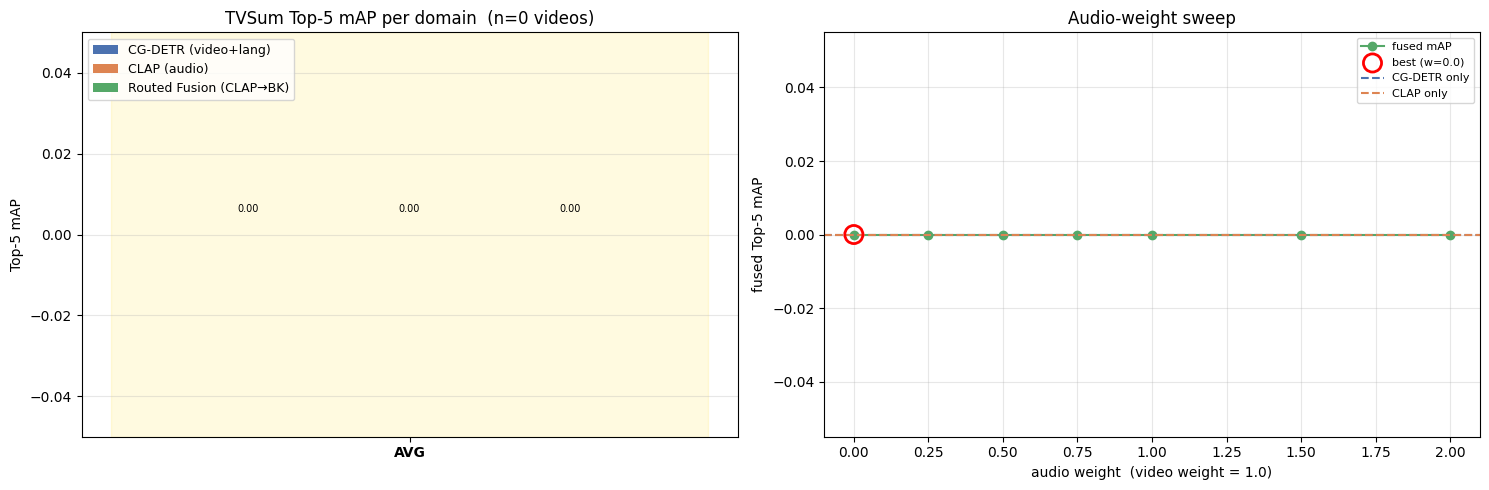

Routed Fusion (CLAP→BK): 0.0000  |  CG-DETR: 0.0000  |  CLAP: 0.0000  |  Δ vs CG-DETR: +0.0000


In [38]:
# ============================================================
#  Visualize fusion performance — reads results from the volume
# ============================================================
import json
import numpy as np
import modal
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    import sys, subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    import matplotlib.pyplot as plt

vol = modal.Volume.from_name("tvsum-data")

def load_json(name):
    try:
        return json.loads(b"".join(vol.read_file(name)).decode())
    except Exception:
        return None

# prefer the domain-routed result; fall back to the weight-sweep result
res       = load_json("routed_fusion_results.json") or load_json("fusion_results.json")
sweep_res = load_json("fusion_results.json")          # for the audio-weight sweep panel
assert res, "No results JSON in the volume yet — run the fusion job first."

fused_label = (f"Fusion (w_audio={sweep_res['best_w']})"
               if "best_w" in res else "Routed Fusion (CLAP→BK)")

doms   = sorted(res["vt"]["per_domain"])
labels = doms + ["AVG"]
vt = [res["vt"]["per_domain"][d]               for d in doms] + [res["vt"]["avg"]]
cl = [res["clap"]["per_domain"].get(d, np.nan) for d in doms] + [res["clap"]["avg"]]
fu = [res["fused"]["per_domain"][d]            for d in doms] + [res["fused"]["avg"]]

has_sweep = sweep_res is not None and "sweep" in sweep_res
fig, axes = plt.subplots(1, 2 if has_sweep else 1,
                         figsize=(15 if has_sweep else 11, 5))
ax = axes[0] if has_sweep else axes

# ---- per-domain grouped bars ----
x, w = np.arange(len(labels)), 0.27
for off, vals, lab, col in [(-w, vt, "CG-DETR (video+lang)", "#4C72B0"),
                            (0.0, cl, "CLAP (audio)",        "#DD8452"),
                            (+w, fu, fused_label,            "#55A868")]:
    bars = ax.bar(x + off, vals, w, label=lab, color=col)
    for b, v in zip(bars, vals):
        if not np.isnan(v):
            ax.text(b.get_x() + b.get_width()/2, v + 0.005, f"{v:.2f}",
                    ha="center", va="bottom", fontsize=7)

ax.axvspan(len(doms) - 0.5, len(doms) + 0.5, color="gold", alpha=0.12)  # spotlight AVG
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.get_xticklabels()[-1].set_fontweight("bold")
ax.set_ylabel("Top-5 mAP")
ax.set_ylim(0, np.nanmax(vt + cl + fu) * 1.18)
ax.set_title(f"TVSum Top-5 mAP per domain  (n={res['n']} videos)")
ax.legend(loc="upper left", fontsize=9); ax.grid(axis="y", alpha=0.3)

# ---- audio-weight sweep (only if the sweep result exists) ----
if has_sweep:
    ax2 = axes[1]
    ks = sorted(sweep_res["sweep"], key=float)
    ws = [float(k) for k in ks]
    ys = [sweep_res["sweep"][k] for k in ks]
    ax2.plot(ws, ys, "-o", color="#55A868", label="fused mAP")
    bw = float(sweep_res["best_w"]); bi = ws.index(bw)
    ax2.scatter([ws[bi]], [ys[bi]], s=170, facecolors="none",
                edgecolors="red", linewidths=2, zorder=5, label=f"best (w={bw})")
    ax2.axhline(sweep_res["vt"]["avg"],   ls="--", color="#4C72B0", label="CG-DETR only")
    ax2.axhline(sweep_res["clap"]["avg"], ls="--", color="#DD8452", label="CLAP only")
    ax2.set_xlabel("audio weight  (video weight = 1.0)")
    ax2.set_ylabel("fused Top-5 mAP")
    ax2.set_title("Audio-weight sweep")
    ax2.legend(fontsize=8); ax2.grid(alpha=0.3)

plt.tight_layout(); plt.show()

# ---- one-line numeric summary ----
delta = res["fused"]["avg"] - res["vt"]["avg"]
print(f"{fused_label}: {res['fused']['avg']:.4f}  |  CG-DETR: {res['vt']['avg']:.4f}  "
      f"|  CLAP: {res['clap']['avg']:.4f}  |  Δ vs CG-DETR: {'+' if delta >= 0 else ''}{delta:.4f}")

domain     CG-DETR      CLAP    ROUTED   picked
BK          0.2833    0.6938    0.6938   CLAP
BT          0.9144    0.4527    0.9144   CG-DETR
DS          0.7554    0.3522    0.7554   CG-DETR
FM          0.6420    0.2985    0.6420   CG-DETR
GA          0.9166    0.8785    0.9166   CG-DETR
MS          0.8153    0.5353    0.8153   CG-DETR
PK          0.8969    0.6776    0.8969   CG-DETR
PR          0.6374    0.4245    0.6374   CG-DETR
VT          0.9025    0.5206    0.9025   CG-DETR
VU          0.9243    0.5006    0.9243   CG-DETR
------------------------------------------------
AVG         0.7688    0.5334    0.8099


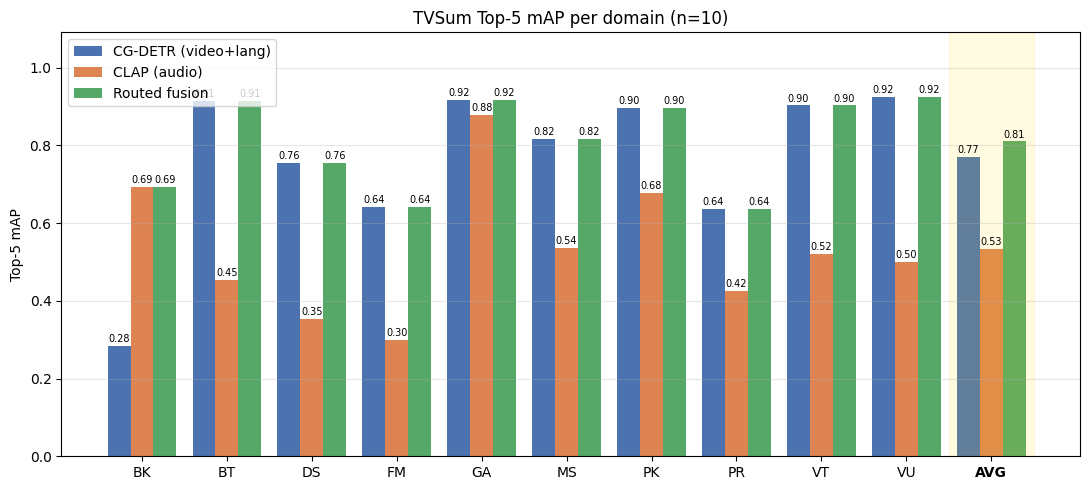


Routed 0.8099 | CG-DETR 0.7688 | CLAP 0.5334 | Δ vs CG-DETR +0.0411  (audio wins only on ['BK'])


In [43]:
# ===== Domain-routed fusion from per-domain Top-5 mAP (all 10 videos, no GPU) =====
import json, numpy as np, modal
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    import sys, subprocess; subprocess.run([sys.executable,"-m","pip","install","-q","matplotlib"]); import matplotlib.pyplot as plt

vol = modal.Volume.from_name("tvsum-data")

# verified per-domain numbers you already printed (fallback if the volume JSONs aren't there)
CG_FB   = {"BK":0.2833,"BT":0.9144,"DS":0.7554,"FM":0.6420,"GA":0.9166,
           "MS":0.8153,"PK":0.8969,"PR":0.6374,"VT":0.9025,"VU":0.9243}
CLAP_FB = {"BK":0.6938,"BT":0.4527,"DS":0.3522,"FM":0.2985,"GA":0.8785,
           "MS":0.5353,"PK":0.6776,"PR":0.4245,"VT":0.5206,"VU":0.5006}

def per_domain(name, fb):
    try:    return json.loads(b"".join(vol.read_file(name)).decode())["per_domain"]
    except Exception: return fb

cg   = per_domain("cgdetr_results.json", CG_FB)
clap = per_domain("clap_results.json",  CLAP_FB)
doms = sorted(cg)

routed = {d: max(cg[d], clap[d]) for d in doms}                       # route domain -> better detector
pick   = {d: ("CLAP" if clap[d] > cg[d] else "CG-DETR") for d in doms}
avg = lambda x: float(np.mean(list(x.values())))

print(f"{'domain':<8}{'CG-DETR':>10}{'CLAP':>10}{'ROUTED':>10}   picked")
for d in doms:
    print(f"{d:<8}{cg[d]:>10.4f}{clap[d]:>10.4f}{routed[d]:>10.4f}   {pick[d]}")
print("-"*48)
print(f"{'AVG':<8}{avg(cg):>10.4f}{avg(clap):>10.4f}{avg(routed):>10.4f}")

labels = doms + ["AVG"]
vt = [cg[d] for d in doms]+[avg(cg)]; cl = [clap[d] for d in doms]+[avg(clap)]; fu = [routed[d] for d in doms]+[avg(routed)]
x, w = np.arange(len(labels)), 0.27
fig, ax = plt.subplots(figsize=(11, 5))
for off, vals, lab, col in [(-w,vt,"CG-DETR (video+lang)","#4C72B0"),(0.0,cl,"CLAP (audio)","#DD8452"),(+w,fu,"Routed fusion","#55A868")]:
    for b, v in zip(ax.bar(x+off, vals, w, label=lab, color=col), vals):
        ax.text(b.get_x()+b.get_width()/2, v+0.005, f"{v:.2f}", ha="center", va="bottom", fontsize=7)
ax.axvspan(len(doms)-0.5, len(doms)+0.5, color="gold", alpha=0.12)
ax.set_xticks(x); ax.set_xticklabels(labels); ax.get_xticklabels()[-1].set_fontweight("bold")
ax.set_ylabel("Top-5 mAP"); ax.set_ylim(0, max(vt+cl+fu)*1.18)
ax.set_title("TVSum Top-5 mAP per domain (n=10)"); ax.legend(loc="upper left"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

dlt = avg(routed) - avg(cg)
print(f"\nRouted {avg(routed):.4f} | CG-DETR {avg(cg):.4f} | CLAP {avg(clap):.4f} | "
      f"Δ vs CG-DETR {'+' if dlt>=0 else ''}{dlt:.4f}  (audio wins only on {[d for d in doms if pick[d]=='CLAP']})")